# GNN-INCM reproduction
An independent reproduction of Huang, Tang and Chen (2022), Knowledge-Based Systems 244, 108538.

**1. Introduction.** We study transductive node classification with scarce, imbalanced supervision. This notebook uses only `main.py` for the model implementation. Saved results are the default demonstration path.

**2. Original paper.** DOI: https://doi.org/10.1016/j.knosys.2022.108538. Read `paper_analysis.md` for equation-level analysis and deviations. Original authorship belongs to the cited authors; this submission is an independent implementation, prepared with AI assistance.

In [1]:
from pathlib import Path
import json, sys, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image
import main as project
ROOT = Path(project.__file__).resolve().parent
RESULTS = ROOT / 'results'
RUN_TRAINING = False  # True runs 15 Cora experiments; may take several minutes.
RUN_DEBUG = False     # True also downloads/loads Cora and executes tests.
print('Single implementation:', project.__file__)
display(pd.read_csv(RESULTS / 'tables' / 'summary.csv'))

Single implementation: C:\Users\vishe\OneDrive\Documents\GNN-INCM-Replication\main.py


,dataset,model,accuracy_mean,accuracy_std,accuracy_count,macro_precision_mean,macro_precision_std,macro_precision_count,macro_recall_mean,macro_recall_std,macro_recall_count,macro_f1_mean,macro_f1_std,macro_f1_count,mcc_mean,mcc_std,mcc_count
0,citeseer,gcn,0.616874,0.071233,3,0.645930,0.140978,3,0.554078,0.060862,3,0.527575,0.067080,3,0.549141,0.073846,3
1,citeseer,gnn_incm,0.609959,0.016773,3,0.637906,0.016504,3,0.571873,0.023876,3,0.574044,0.010772,3,0.538514,0.019445,3
2,cora,gcn,0.473855,0.264768,3,0.530076,0.323342,3,0.407584,0.253899,3,0.403240,0.263002,3,0.368966,0.322383,3
3,cora,gnn_incm,0.647075,0.026292,3,0.742021,0.036484,3,0.660494,0.024722,3,0.643218,0.020654,3,0.603265,0.017598,3
4,cora,no_cluster,0.647075,0.026292,3,0.742021,0.036484,3,0.660494,0.024722,3,0.643218,0.020654,3,0.603265,0.017598,3
5,cora,no_hard,0.671741,0.045549,3,0.750350,0.035747,3,0.694147,0.033183,3,0.670663,0.040631,3,0.631284,0.042809,3
6,cora,no_reconstruction,0.646230,0.028782,3,0.740741,0.033082,3,0.662420,0.026299,3,0.643236,0.022466,3,0.603036,0.020510,3
7,pubmed,gcn,0.755044,0.049148,3,0.801376,0.018532,3,0.737093,0.051187,3,0.746650,0.051051,3,0.634665,0.062974,3
8,pubmed,gnn_incm,0.758472,0.003854,3,0.764337,0.004971,3,0.785519,0.004508,3,0.755488,0.004614,3,0.649417,0.006402,3


## 3. Problem definition
The graph provides features and citation relationships for all nodes. Only the training subset supplies labels to the loss. Minority classes receive fewer labeled examples under uniform sampling. Validation selects checkpoints; test labels are reserved for final evaluation.

## 4. Dataset statistics
Paper statistics and actual processed counts are distinguished below. CiteSeer unknown labels are excluded from supervised masks without removing their graph nodes.

In [2]:
stats=[]
for dataset in project.EXPECTED:
    files=sorted((RESULTS/'logs').glob(f'{dataset}_*_dataset.json'))
    if files:
        d=json.loads(files[0].read_text())
        stats.append({k:v for k,v in d.items() if k not in ['sha256','class_counts','source']})
display(pd.DataFrame(stats))

,dataset,nodes,features,classes,undirected_edges,directed_entries,paper_links,unknown_labels
0,cora,2708,1433,7,5278,10556,5429,0
1,citeseer,3327,3703,6,4552,9104,4732,15
2,pubmed,19717,500,3,44324,88648,44338,0


## 5. Preprocessing
Feature rows are normalized; the graph is undirected and deduplicated. Message passing adds self-loops and symmetric normalization. Seeded permutations allocate floor(3% of known labels) to training and floor(10% of the remainder) to validation.

## 6. Baseline GCN
Two bias-free linear maps, 100 hidden units, ReLU, dropout 0.3, and K-dimensional output. The baseline uses unweighted supervised cross-entropy.

## 7. GNN-INCM architecture
The same GCN supplies embeddings to classification, ECO clustering, and GRO reconstruction. A shared objective trains its weights.

In [3]:
model=project.GCN(1433,100,7,.3)
print(model)
print('Trainable parameters:',sum(p.numel() for p in model.parameters()))

GCN(
  (first): Linear(in_features=1433, out_features=100, bias=False)
  (second): Linear(in_features=100, out_features=7, bias=False)
)
Trainable parameters: 144000


## 8. ECO
K-means initializes fixed centers using training-node embeddings. Student-t assignments Q are sharpened into detached targets P. KL(P||Q) provides unsupervised guidance across all graph nodes. Center update details are not specified by the paper; our fixed-center choice is an assumption.

## 9. GRO
An inner-product decoder predicts edge probabilities. We use equal numbers of sampled positive edges and verified negative edges. This avoids a dense PubMed adjacency but changes the paper's full-pair loss weighting.

## 10. Hard sample weighting
Weights start uniformly in [0.5,1]. They are divided by gamma for agreement between argmax Q and argmax P, and multiplied for disagreement. The floor is 0.5; gamma=1.01 and cap=100 are implementation choices. These are cluster-difficulty weights, not focal loss.

## 11. HSKDM
Analyzed but **not implemented**. The paper jointly trains multiple models with directed distribution KL and weighted triplet alignment. None of our results are HSKDM results.

## 12. Mathematical equations
$$O=\widetilde A\,\mathrm{ReLU}(\widetilde A XW_0)W_1,\qquad \widetilde A=D^{-1/2}(A+I)D^{-1/2}.$$
$$q_{ij}=\frac{(1+\|o_i-u_j\|^2)^{-1}}{\sum_x(1+\|o_i-u_x\|^2)^{-1}},\quad p_{ij}=\frac{q_{ij}^2/\sum_iq_{ij}}{\sum_x(q_{ix}^2/\sum_iq_{ix})}.$$
$$\widehat A_{ij}=\sigma(o_i^To_j),\quad L=L_{classification}+L_{clustering}+L_{reconstruction}.$$
We correct apparent loss-sign errors, apply positive inverse-frequency class weights and average each component over its own samples. See the analysis for the consequences.

## 13. Fast debugging
The completed debug record includes a controlled loss-decrease test, nonzero finite gradients, hard-weight direction checks, negative-edge validation, and checkpoint round-trip equality. Debug metrics are excluded from experiment summaries.

In [4]:
if RUN_DEBUG:
    project.main(['--mode','debug'])
status=RESULTS/'debug'/'debug_status.json'
print(status.read_text() if status.exists() else 'Run python main.py --mode debug to generate the test record.')

{
  "status": "passed",
  "controlled_initial_loss": 9.0,
  "controlled_final_loss": 0.001196303521282971,
  "checks": [
    "dataset dimensions",
    "holdout-label invariance",
    "disjoint splits",
    "sparse normalization",
    "forward pass",
    "finite loss",
    "nonzero finite gradients",
    "parameter update",
    "soft assignments",
    "target distribution",
    "easy/hard update",
    "negative edges",
    "reconstruction",
    "metrics",
    "checkpoint reload"
  ]
}


## 14. Training
The CLI defaults use at most 1000 epochs and patience 200. The saved checkpoint maximizes validation macro F1. Re-running a dataset/model/seed replaces its artifacts, so use a separate output directory for new configurations. Set RUN_TRAINING=True above to rerun Cora; the default preserves the completed submission.

In [5]:
if RUN_TRAINING:
    project.main(['--mode','all','--dataset','cora','--output',str(ROOT/'results_rerun')])
else:
    print('Using actual saved experiment results. No training was performed by this notebook execution.')

Using actual saved experiment results. No training was performed by this notebook execution.


## 15. Cora results
The following rows are actual runs, including the baseline, core model and three ablations. Mean and sample standard deviation are computed from these rows.

In [6]:
runs=pd.read_csv(RESULTS/'tables'/'individual_runs.csv')
display(runs[runs.dataset=='cora'])
display(runs[runs.dataset=='cora'].groupby('model')[['accuracy','macro_f1','mcc']].agg(['mean','std','count']))

,dataset,model,seed,accuracy,macro_precision,macro_recall,macro_f1,mcc,best_epoch,epochs_ran,seconds
6,cora,gcn,42,0.526004,0.693063,0.397160,0.431476,0.438688,50,250,7.308342
7,cora,gcn,43,0.708668,0.739489,0.666534,0.650985,0.650783,86,286,8.673356
8,cora,gcn,44,0.186892,0.157676,0.159058,0.127260,0.017427,2,202,5.998179
9,cora,gnn_incm,42,0.636786,0.742357,0.643135,0.631847,0.598133,213,413,15.704700
10,cora,gnn_incm,43,0.676956,0.705370,0.688800,0.667059,0.622859,33,233,8.996550
11,cora,gnn_incm,44,0.627484,0.778337,0.649547,0.630747,0.588804,305,505,17.509123
12,cora,no_cluster,42,0.636786,0.742357,0.643135,0.631847,0.598133,213,413,13.806586
13,cora,no_cluster,43,0.676956,0.705370,0.688800,0.667059,0.622859,33,233,7.642186
14,cora,no_cluster,44,0.627484,0.778337,0.649547,0.630747,0.588804,305,505,16.408396
15,cora,no_hard,42,0.639746,0.711875,0.677894,0.635622,0.600758,36,236,8.208740


accuracy                  macro_f1                  \
                       mean       std count      mean       std count   
model                                                                   
gcn                0.473855  0.264768     3  0.403240  0.263002     3   
gnn_incm           0.647075  0.026292     3  0.643218  0.020654     3   
no_cluster         0.647075  0.026292     3  0.643218  0.020654     3   
no_hard            0.671741  0.045549     3  0.670663  0.040631     3   
no_reconstruction  0.646230  0.028782     3  0.643236  0.022466     3   

                        mcc                  
                       mean       std count  
model                                        
gcn                0.368966  0.322383     3  
gnn_incm           0.603265  0.017598     3  
no_cluster         0.603265  0.017598     3  
no_hard            0.631284  0.042809     3  
no_reconstruction  0.603036  0.020510     3

## 16. CiteSeer and PubMed
Only completed experiments appear; an empty selection indicates that no run was completed.

In [7]:
display(runs[runs.dataset!='cora'])

,dataset,model,seed,accuracy,macro_precision,macro_recall,macro_f1,mcc,best_epoch,epochs_ran,seconds
0,citeseer,gcn,42,0.562241,0.678518,0.508526,0.505294,0.496624,43,243,15.808426
1,citeseer,gcn,43,0.590941,0.491512,0.530508,0.474470,0.517220,450,650,40.363677
2,citeseer,gcn,44,0.697441,0.767760,0.623199,0.602960,0.633578,196,396,23.328440
3,citeseer,gnn_incm,42,0.593015,0.634820,0.548171,0.563708,0.519143,45,245,16.018738
4,citeseer,gnn_incm,43,0.610304,0.655735,0.571527,0.573219,0.538368,154,354,23.252961
5,citeseer,gnn_incm,44,0.626556,0.623164,0.595921,0.585205,0.558032,259,459,31.829791
21,pubmed,gcn,42,0.712211,0.787225,0.683984,0.697000,0.575405,81,281,35.258531
22,pubmed,gcn,43,0.808702,0.822353,0.786112,0.798995,0.700790,111,311,38.064164
23,pubmed,gcn,44,0.744220,0.794551,0.741183,0.743953,0.627799,213,413,52.663096
24,pubmed,gnn_incm,42,0.761008,0.760912,0.784172,0.759487,0.646416,53,253,34.195515


## 17. Evaluation metrics
Accuracy, macro precision/recall/F1 and multiclass MCC are computed on the saved test mask. Macro averages include every class with zero division handled as zero. The paper's F1 averaging convention is unspecified. The next table exposes class-level support and performance.

In [8]:
display(pd.read_csv(RESULTS/'metrics'/'cora_gnn_incm_seed42_per_class.csv'))

,class_id,precision,recall,f1,support
0,0,0.357992,0.906355,0.513258,299
1,1,0.743243,0.555556,0.635838,198
2,2,0.943114,0.849057,0.893617,371
3,3,0.970492,0.408276,0.574757,725
4,4,0.542125,0.819945,0.652701,361
5,5,0.776786,0.677043,0.723493,257
6,6,0.862745,0.285714,0.429268,154


## 18. Confusion matrices
Rows are true class IDs and columns predicted class IDs. These reflect the best-validation checkpoint rather than the final training epoch.

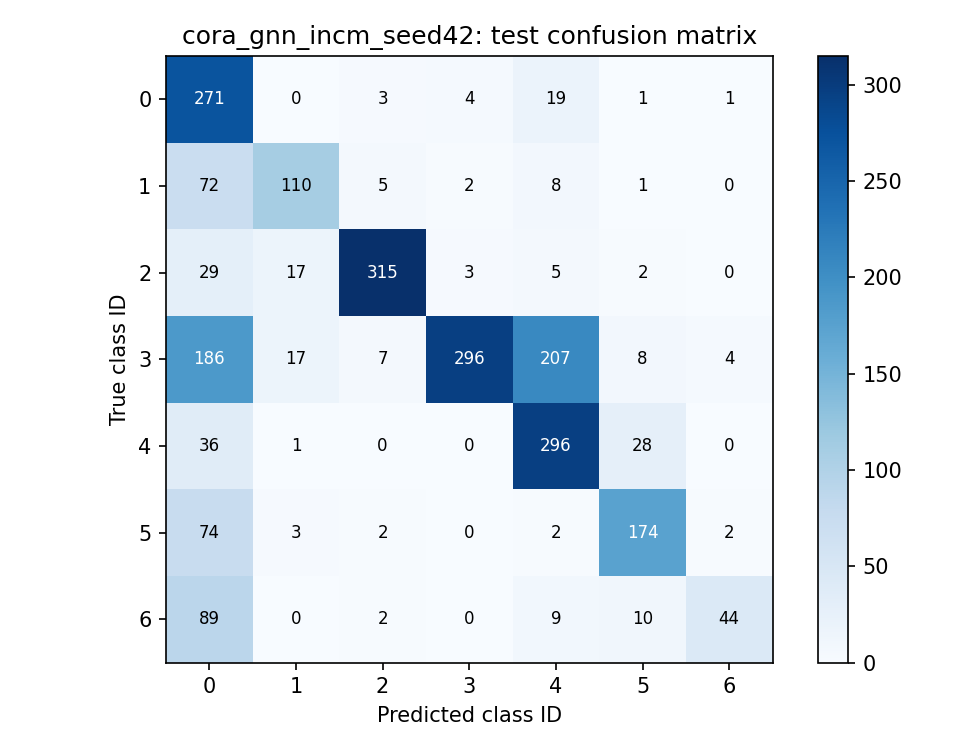

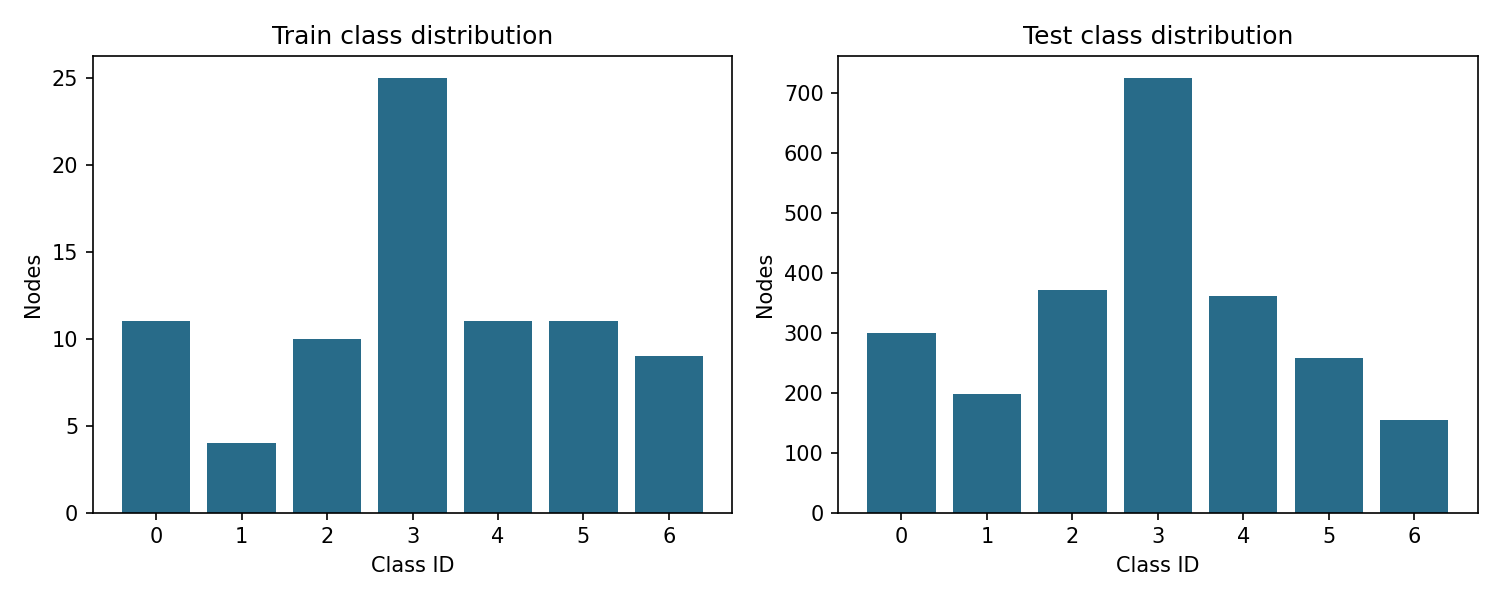

In [9]:
display(Image(filename=str(RESULTS/'figures'/'cora_gnn_incm_seed42_confusion.png')))
display(Image(filename=str(RESULTS/'figures'/'cora_gnn_incm_seed42_classes.png')))

## 19. Training curves and ablations
Loss components have different sample normalizations. Flat or tiny clustering loss indicates weak clustering guidance; test performance should not be inferred from training loss alone.

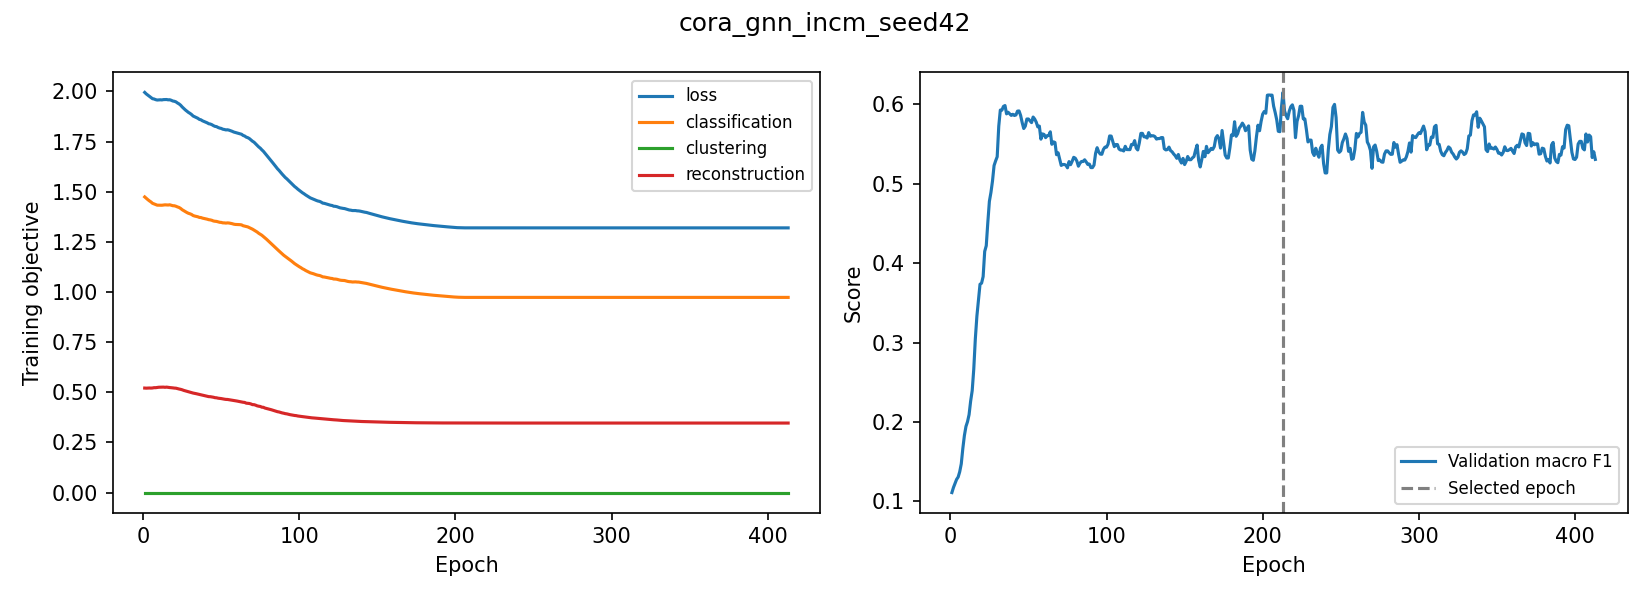

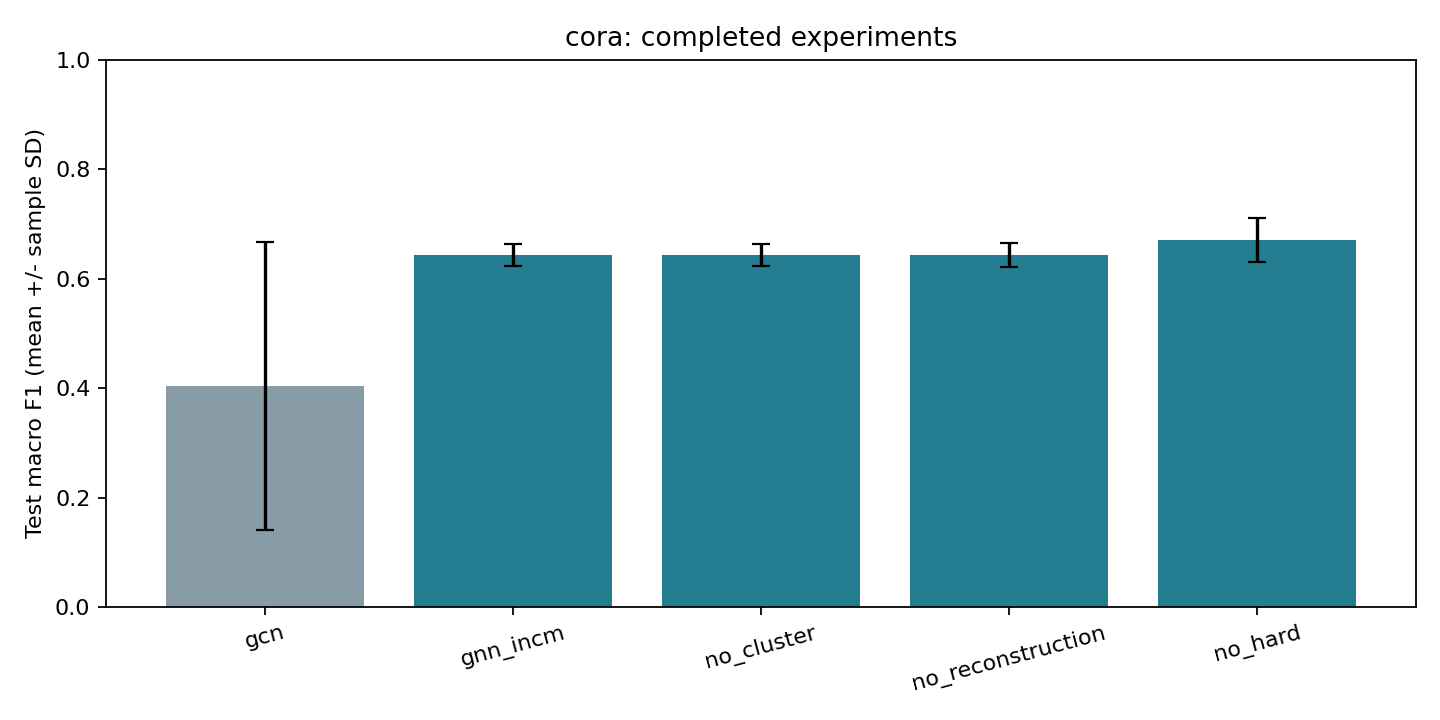

In [10]:
display(Image(filename=str(RESULTS/'figures'/'cora_gnn_incm_seed42_curves.png')))
display(Image(filename=str(RESULTS/'figures'/'cora_comparison.png')))

## 20. Paper-versus-our-results table
Paper values are Table 2 means and SDs over ten runs. Our F1 is explicitly macro F1; the comparison is descriptive because the original averaging is unclear. Missing runs remain marked, never imputed.

In [11]:
display(pd.read_csv(RESULTS/'tables'/'paper_vs_ours.csv'))

,Dataset,Model,Metric,Paper Result,Our Result,Difference
0,cora,gcn,F1,0.6861 +/- 0.0023,0.40324,-0.28286
1,cora,gcn,MCC,0.6146 +/- 0.0014,0.36897,-0.24563
2,cora,gnn_incm,F1,0.7508 +/- 0.0045,0.64322,-0.10758
3,cora,gnn_incm,MCC,0.7237 +/- 0.0051,0.60327,-0.12043
4,cora,no_cluster,F1,0.7407 +/- 0.0071,0.64322,-0.09748
5,cora,no_cluster,MCC,0.7141 +/- 0.0061,0.60327,-0.11083
6,cora,no_reconstruction,F1,0.7431 +/- 0.0064,0.64324,-0.09986
7,cora,no_reconstruction,MCC,0.7143 +/- 0.0049,0.60304,-0.11126
8,cora,no_hard,F1,0.7439 +/- 0.0058,0.67066,-0.07324
9,cora,no_hard,MCC,0.7131 +/- 0.0057,0.63128,-0.08182


## 21. Discussion
Read the generated reproduction report alongside these results. A runnable core algorithm does not establish numerical reproduction. High variance and gaps from the paper must be reported rather than concealed by selecting a favorable seed.

## 22. Limitations
Three seeds rather than ten; CPU training; sampled balanced reconstruction; mean-normalized losses; assumed feature normalization, gamma and center handling; different baseline settings; unavailable author code; unclear original F1 aggregation. HSKDM remains unimplemented. No test-based hyperparameter search was conducted.

## 23. Conclusion
The submission provides an executable single-file practical reproduction with genuine data and auditable artifacts. Its results should be interpreted under the documented deviations, not as confirmation of the original headline performance.

References: Huang et al. (2022), DOI above; Kipf & Welling (2017), https://arxiv.org/abs/1609.02907; Planetoid data, https://github.com/kimiyoung/planetoid.